# Multi-Component, Norm-Preserving Style Steering — final notebook
*(LaMP_4 News Headline · LaMP_5 Scholarly Title · LaMP_7 Tweet Paraphrasing)*

**What this notebook runs** (the original StyleVector method is **not** run here):

| Name | What it is |
|---|---|
| `base` | LLaMA-2-7B-chat with no steering |
| `pca_add` | our style vector: top-3 principal components of the user's contrastive differences, added to the hidden state |
| `pca_np` | **our full method**: same, but the activation is rescaled back to its original norm |
| `random_np` | control: a *random* direction at the same strength as `pca_np`, to show that any gain is not just "poking the model" |

**Comparison with the paper.** We do not re-run StyleVector. We take the paper's reported improvement of StyleVector over the
non-personalised model (Table 2, "Improv." column) and compare it with *our* improvement over *our* non-personalised model,
with a 95 % confidence interval. (Different model precision, user sample and output cleaning mean this is indicative, not like-for-like.)

**Protocol.** Users are split into disjoint *validation* users (used only to pick layer and strength) and *test* users (used only for the final numbers).
Strength is $\rho=\lVert p\rVert/\lVert h\rVert$, the size of the push relative to the activation. The setting is chosen by the **paired gain over no steering** on the validation users.

## Part 0 — Setup

In [1]:
# Cell 0.1 — Working directory (local lab PC, no Drive/Kaggle mount needed)
import os
PROJECT_DIR = os.path.expanduser('~/stylevector_project')
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

Working directory: /home/user/stylevector_project


In [2]:
# Cell 0.2 — Install dependencies
!pip install -q transformers accelerate bitsandbytes rouge-score nltk huggingface_hub --upgrade


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
# Cell 0.3 — NLTK data (with fallback if blocked)
import os
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"
import nltk
try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except AttributeError:
    pass

NLTK_OK = True
try:
    nltk.download('wordnet', quiet=True)
    nltk.download('punkt', quiet=True)
    nltk.download('punkt_tab', quiet=True)
    nltk.download('omw-1.4', quiet=True)
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score
    _ = word_tokenize("test sentence")
    _ = meteor_score([["test", "sentence"]], ["test", "sentence"])
    print("NLTK data OK -- using real METEOR + real tokenizer.")
except Exception as e:
    NLTK_OK = False
    print(f"NLTK data unavailable ({e}). Falling back to unigram-F1 METEOR proxy.")

/home/user/stylevector_env/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


NLTK data OK -- using real METEOR + real tokenizer.


In [4]:
# Cell 0.4 — Imports
import json, time, re, random
from pathlib import Path

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import logging
logging.getLogger("transformers").setLevel(logging.ERROR)

plt.rcParams["figure.dpi"] = 110
RNG_SEED = 42
print("Imports OK. CUDA available:", torch.cuda.is_available())
from collections import OrderedDict
import os, zlib
from matplotlib.ticker import NullFormatter

Imports OK. CUDA available: True


/home/user/stylevector_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — Data

In [5]:
%%writefile download_lamp.sh
#!/usr/bin/env bash
set -euo pipefail
OUT_DIR="${1:-./data/lamp}"
BASE_URL="https://ciir.cs.umass.edu/downloads/LaMP"

declare -A TASKS=(
  [LaMP_4]="News Headline Generation"
  [LaMP_5]="Scholarly Title Generation"
  [LaMP_7]="Tweet Paraphrasing"
)
SPLITS=(train dev test)
FILE_TYPES=(questions outputs)

for task in "${!TASKS[@]}"; do
  echo "== ${task}: ${TASKS[$task]} =="
  for split in "${SPLITS[@]}"; do
    mkdir -p "${OUT_DIR}/${task}/${split}"
    for ftype in "${FILE_TYPES[@]}"; do
      url="${BASE_URL}/${task}/${split}/${split}_${ftype}.json"
      out="${OUT_DIR}/${task}/${split}/${split}_${ftype}.json"
      if [ -f "${out}" ]; then
        echo "  [cached] ${out}"
        continue
      fi
      echo "  fetching ${url}"
      if curl -sSf --retry 3 --max-time 60 -o "${out}" "${url}"; then
        echo "    saved -> ${out}"
      else
        echo "    [skip] not publicly available: ${url}"
        rm -f "${out}"
      fi
    done
  done
done
echo "Done."

Overwriting download_lamp.sh


In [6]:
# Cell 1.2 — Run the download (idempotent, safe to re-run)
!bash download_lamp.sh ./data/lamp
!ls -la ./data/lamp/LaMP_5/dev/

== LaMP_7: Tweet Paraphrasing ==
  [cached] ./data/lamp/LaMP_7/train/train_questions.json
  [cached] ./data/lamp/LaMP_7/train/train_outputs.json
  [cached] ./data/lamp/LaMP_7/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_7/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_7/test/test_questions.json
  [cached] ./data/lamp/LaMP_7/test/test_outputs.json
== LaMP_4: News Headline Generation ==
  [cached] ./data/lamp/LaMP_4/train/train_questions.json
  [cached] ./data/lamp/LaMP_4/train/train_outputs.json
  [cached] ./data/lamp/LaMP_4/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_4/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_4/test/test_questions.json
  [cached] ./data/lamp/LaMP_4/test/test_outputs.json
== LaMP_5: Scholarly Title Generation ==
  [cached] ./data/lamp/LaMP_5/train/train_questions.json
  [cached] ./data/lamp/LaMP_5/train/train_outputs.json
  [cached] ./data/lamp/LaMP_5/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_5/dev/dev_outputs.json
  [cached] ./data/lamp/

In [7]:
%%writefile load_lamp_data.py
import json
from pathlib import Path
from typing import Optional

TASK_PROFILE_FIELDS = {
    "LaMP_4": ("text", "title"),
    "LaMP_5": ("abstract", "title"),
    "LaMP_7": (None, "text"),
}


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def build_gold_lookup(outputs_json: dict) -> dict:
    return {item["id"]: item["output"] for item in outputs_json["golds"]}


def make_synthetic_input(y_text: str) -> str:
    return "Write a short tweet."


def load_task_split(data_dir: Path, task: str, split: str,
                     max_users: Optional[int] = None,
                     max_history_per_user: Optional[int] = None,
                     min_history_len: int = 3):
    assert task in TASK_PROFILE_FIELDS, f"Unsupported/unmapped task: {task}"
    input_field, output_field = TASK_PROFILE_FIELDS[task]

    q_path = data_dir / task / split / f"{split}_questions.json"
    o_path = data_dir / task / split / f"{split}_outputs.json"

    questions = load_json(q_path)
    gold_lookup = {}
    if o_path.exists():
        gold_lookup = build_gold_lookup(load_json(o_path))

    for q in questions:
        if q["profile"]:
            sample = q["profile"][0]
            print(f"[{task}/{split}] sample profile item keys: {list(sample.keys())}")
            if output_field not in sample:
                raise KeyError(f"Expected output field '{output_field}' not found in {sample}")
            break

    users = {}
    for q in questions:
        user_id = q["id"]
        history = []
        for item in q["profile"]:
            y_i = item.get(output_field)
            if y_i is None:
                continue
            x_i = item.get(input_field) if input_field is not None else make_synthetic_input(y_i)
            history.append((x_i, y_i))

        if len(history) < min_history_len:
            continue
        if max_history_per_user is not None:
            history = history[:max_history_per_user]

        gold = gold_lookup.get(user_id)
        if gold is None:
            continue

        users[user_id] = {"history": history, "query_input": q["input"], "query_gold": gold}
        if max_users is not None and len(users) >= max_users:
            break

    return users

Overwriting load_lamp_data.py


In [8]:
# Cell 1.4 — Load the three tasks and make DISJOINT validation / test user sets
from load_lamp_data import load_task_split
from pathlib import Path

TASKS = ["LaMP_4", "LaMP_5", "LaMP_7"]
DATA_DIR = Path("./data/lamp")
MAX_HISTORY_PER_USER_BY_TASK = {"LaMP_4": 30, "LaMP_5": 30, "LaMP_7": 15}

N_VAL_USERS  = 60     # users per task used ONLY to choose layer and strength
N_TEST_USERS = 300    # users per task used ONLY for the final numbers (more users = tighter confidence intervals)

val_users, test_users = {}, {}
for task in TASKS:
    cap = MAX_HISTORY_PER_USER_BY_TASK[task]
    pool = load_task_split(data_dir=DATA_DIR, task=task, split="dev", max_users=None,
                           max_history_per_user=cap, min_history_len=3)
    ids = list(pool.keys())
    random.Random(RNG_SEED).shuffle(ids)
    val_ids, test_ids = ids[:N_VAL_USERS], ids[N_VAL_USERS:N_VAL_USERS + N_TEST_USERS]
    assert not set(val_ids) & set(test_ids)
    val_users[task]  = {u: pool[u] for u in val_ids}
    test_users[task] = {u: pool[u] for u in test_ids}
    print(f"{task}: pool={len(pool)}  validation={len(val_ids)}  test={len(test_ids)}  history cap={cap}")

[LaMP_4/dev] sample profile item keys: ['text', 'title', 'id']
LaMP_4: pool=1925  validation=60  test=300  history cap=30
[LaMP_5/dev] sample profile item keys: ['title', 'abstract', 'id']
LaMP_5: pool=2500  validation=60  test=300  history cap=30
[LaMP_7/dev] sample profile item keys: ['text', 'id']
LaMP_7: pool=1500  validation=60  test=300  history cap=15


## Part 2 — Model (LLaMA-2-7B-chat, 4-bit)

In [9]:
# Cell 2.1 — Clean up any stale GPU memory from a previous session first
import gc, torch
for var_name in ["model", "tokenizer"]:
    if var_name in dir():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
    print(f"GPU memory reserved:  {torch.cuda.memory_reserved()/1e9:.2f} GB")

GPU memory allocated: 0.00 GB
GPU memory reserved:  0.00 GB


In [10]:
# Cell 2.2 — Load tokenizer + model (4-bit NF4 -- see Part 0 note on why)
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_NAME = "meta-llama/Llama-2-7b-chat-hf"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)
# To match the paper's exact 8-bit setup instead (needs a GPU with more
# headroom, e.g. 16GB+), comment out the block above and use:
#   quant_config = BitsAndBytesConfig(load_in_8bit=True)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    quantization_config=quant_config,
)
model.eval()
model.generation_config.max_length = 1024  # avoid huge KV-cache pre-allocation on tight VRAM

N_LAYERS = len(model.model.layers)
HIDDEN_DIM = model.config.hidden_size
print(f"Loaded {MODEL_NAME}")
print(f"Layers: {N_LAYERS} | Hidden dim: {HIDDEN_DIM}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 291/291 [00:13<00:00, 22.34it/s]

Loaded meta-llama/Llama-2-7b-chat-hf
Layers: 32 | Hidden dim: 4096
GPU memory allocated: 4.19 GB


In [11]:
# Cell 2.3 — Prompt formatting (chat template, [INST] fallback)
def build_input_ids(tokenizer, prompt, device):
    messages = [{"role": "user", "content": prompt}]
    try:
        inputs = tokenizer.apply_chat_template(
            messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
        )
        return inputs["input_ids"].to(device)
    except Exception:
        formatted = f"<s>[INST] {prompt} [/INST]"
        return tokenizer(formatted, return_tensors="pt").input_ids.to(device)

_test = build_input_ids(tokenizer, "Say hello.", model.device)
print("Prompt formatting OK, input shape:", _test.shape)

Prompt formatting OK, input shape: torch.Size([1, 11])


## Part 3 — Core functions

In [12]:
# Cell 3.1 — Task prompts (exact wording from the paper's Appendix E)
TASK_PROMPTS = {
    "LaMP_4": lambda text: f'Generate a headline for the following article "{text}".',
    "LaMP_5": lambda text: f'Generate a title for the following abstract of a paper "{text}".',
    "LaMP_7": lambda text: f'Paraphrase the following tweet without any explanation before or after it "{text}".',
}

In [13]:
# Cell 3.2 — Output cleaner: drop "Sure! Here is...", keep the first line, strip quotes (same for every config)
CLEAN_GENERIC, CLEAN_PREDS = True, True
_LEAD = r"^(sure|certainly|of course|absolutely|okay|ok|here)\b"

def clean_output(text):
    t = (text or "").strip()
    lines = [l.strip() for l in t.split("\n") if l.strip()]
    if len(lines) > 1 and re.match(_LEAD, lines[0], re.I) and re.search(r"[:!]\s*$", lines[0]):
        lines = lines[1:]
    if not lines:
        return ""
    t = re.sub(r"^(sure|certainly|of course|absolutely)[!,.]?\s*", "", lines[0], flags=re.I)
    t = re.sub(r"^here('s| is| are)\b[^:\n]{0,80}:\s*", "", t, flags=re.I)
    return t.strip().strip("\"'\u201c\u201d\u2018\u2019*` ").strip()

def is_degenerate(text):
    toks = re.findall(r"\w+|[^\w\s]", (text or "").lower())
    return len(toks) == 0 or (len(toks) >= 8 and len(set(toks)) / len(toks) < 0.4)

assert clean_output('Sure! Here is a headline: "Teens Online: Tips"') == "Teens Online: Tips"
assert clean_output("Sure! Here's a title:\n\nDeep Nets\n\nHope this helps!") == "Deep Nets"
print("cleaner OK")

cleaner OK


In [14]:
# Cell 3.3 — Generation (optionally steered)
#   additive:         h' = h + rho*||h||*d
#   norm-preserving:  h' = ||h|| * (h + rho*||h||*d) / ||h + rho*||h||*d||
def make_steering_hook(direction, rho, norm_preserve=False):
    direction = direction.clone().float()
    def hook(module, inp, output):
        is_tuple = isinstance(output, tuple)
        hs = (output[0] if is_tuple else output).clone()
        h = hs[:, -1:, :].float()                                   # last prompt token, then every generated token
        hn = h.norm(dim=-1, keepdim=True)
        new = h + rho * hn * direction.to(hs.device)
        if norm_preserve:
            new = new * (hn / new.norm(dim=-1, keepdim=True).clamp_min(1e-6))
        hs[:, -1:, :] = new.to(hs.dtype)
        return (hs,) + tuple(output[1:]) if is_tuple else hs
    return hook

def generate_from_ids(input_ids, max_new_tokens=40, layer_idx=None, direction=None, rho=0.0, norm_preserve=False):
    handle = None
    if direction is not None:
        handle = model.model.layers[layer_idx].register_forward_hook(make_steering_hook(direction, rho, norm_preserve))
    try:
        with torch.no_grad():
            out = model.generate(input_ids, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tokenizer.eos_token_id)
    finally:
        if handle is not None:
            handle.remove()
    return tokenizer.decode(out[0][input_ids.shape[1]:], skip_special_tokens=True).strip()

In [15]:
# Cell 3.4 — Contrastive differences (authentic minus generic) for several layers in one pass, cached on disk.
# Cache writes are atomic and loads are safe, so an interrupted run cannot corrupt the cache.
def get_last_token_activations(text, layer_idxs, max_len=512):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_len).to(model.device)
    captured, handles = {}, []
    def make_hook(L):
        def hook(module, inp, output):
            hs = output[0] if isinstance(output, tuple) else output
            captured[L] = hs[:, -1, :].detach().float().cpu().squeeze(0)
        return hook
    for L in layer_idxs:
        handles.append(model.model.layers[L].register_forward_hook(make_hook(L)))
    try:
        with torch.no_grad():
            model(**inputs)
    finally:
        for h in handles:
            h.remove()
    return captured

def compute_user_deltas(history, task, max_history, max_gen_tokens):
    prompt_fn, per_layer = TASK_PROMPTS[task], {L: [] for L in DELTA_LAYERS}
    for x_i, y_i in history[:max_history]:
        if not x_i or not y_i:
            continue
        raw = generate_from_ids(build_input_ids(tokenizer, prompt_fn(x_i), model.device), max_gen_tokens)
        y_hat = (clean_output(raw) if CLEAN_GENERIC else raw) or raw
        a_p = get_last_token_activations(f"{x_i} {y_i}", DELTA_LAYERS)
        a_n = get_last_token_activations(f"{x_i} {y_hat}", DELTA_LAYERS)
        for L in DELTA_LAYERS:
            per_layer[L].append(a_p[L] - a_n[L])
    return {L: torch.stack(v) for L, v in per_layer.items()} if per_layer[DELTA_LAYERS[0]] else None

def delta_cache_path(task, uid):
    return DELTA_DIR / f"{task}_h{MAX_HISTORY_PER_USER_BY_TASK[task]}_{str(uid).replace('/', '_')}.pt"

def safe_load_deltas(path):
    try:
        blob = torch.load(path, map_location="cpu")
        return {L: t.float() for L, t in blob["deltas"].items()}
    except Exception:
        return None

def get_or_compute_deltas(task, uid, history, max_history, max_gen_tokens):
    path = delta_cache_path(task, uid)
    if path.exists():
        d = safe_load_deltas(path)
        if d is not None and all(L in d for L in DELTA_LAYERS):
            return d
        path.unlink()
    deltas = compute_user_deltas(history, task, max_history, max_gen_tokens)
    if deltas is None:
        return None
    tmp = path.with_name(path.name + ".tmp")
    torch.save({"deltas": {L: t.half() for L, t in deltas.items()}}, tmp)
    os.replace(tmp, path)
    return {L: t.float() for L, t in deltas.items()}

In [16]:
# Cell 3.5 — OUR style direction: top-k PCA of {Delta_i} U {-Delta_i}, weighted by sqrt(eigenvalue)
def style_components(deltas, k):
    """Top-k eigenvectors of sum_i D_i D_i^T + (-D_i)(-D_i)^T = 2 D^T D (via SVD); unit norm, orthogonal,
    sign-aligned with the mean difference (the symmetric set has no natural sign)."""
    D = deltas.float()
    _, S, Vh = torch.linalg.svd(D, full_matrices=False)
    k_eff = min(k, Vh.shape[0])
    V, lam = Vh[:k_eff], 2.0 * S[:k_eff] ** 2
    proj = V @ D.mean(0)
    return V * torch.where(proj >= 0, torch.ones_like(proj), -torch.ones_like(proj))[:, None], lam

def _unit(v):
    n = v.norm()
    return v / n if n > 0 else v

def build_direction(deltas, method, k=3, uid=0):
    """Unit-norm steering direction. 'pca': sum_j w_j v_j, w_j ~ sqrt(lambda_j). 'random': seeded random control."""
    D = deltas.float()
    if method == "random":
        g = torch.Generator().manual_seed(zlib.crc32(str(uid).encode()) % (2 ** 31))
        return _unit(torch.randn(D.shape[1], generator=g))
    V, lam = style_components(D, k)
    w = lam.sqrt()
    if w.norm() == 0:
        return torch.zeros(D.shape[1])
    return _unit(((w / w.norm())[:, None] * V).sum(0))

In [17]:
# Cell 3.6 — Self-test (no model needed)
import torch.nn as nn, tempfile
torch.manual_seed(0)
D = torch.randn(12, 64) + 2.0 * torch.randn(1, 64)
V, lam = style_components(D, 5)
assert torch.allclose(V @ V.T, torch.eye(5), atol=1e-4) and (V @ D.mean(0) >= 0).all()
M = sum(torch.outer(d, d) + torch.outer(-d, -d) for d in D)
assert torch.allclose(torch.linalg.eigvalsh(M).flip(0)[:5], lam, rtol=1e-3)
d = build_direction(D, "pca", 3); r1 = build_direction(D, "random", uid=1)
assert abs(d.norm().item() - 1) < 1e-4 and abs(r1.norm().item() - 1) < 1e-4
assert torch.equal(r1, build_direction(D, "random", uid=1)) and not torch.equal(r1, build_direction(D, "random", uid=2))

class _Dummy(nn.Module):
    def forward(self, x): return (x,)
layer, h = _Dummy(), torch.randn(2, 6, 64) * 3
def run(**kw):
    hd = layer.register_forward_hook(make_steering_hook(d, **kw)); out = layer(h)[0]; hd.remove(); return out
o = run(rho=0.3)
assert torch.allclose((o[:, -1] - h[:, -1]).norm(dim=-1), 0.3 * h[:, -1].norm(dim=-1), atol=1e-4) and torch.equal(o[:, :-1], h[:, :-1])
o = run(rho=0.3, norm_preserve=True)
assert torch.allclose(o[:, -1].norm(dim=-1), h[:, -1].norm(dim=-1), atol=1e-4)
print("self-tests passed")

self-tests passed


In [18]:
# Cell 3.6 — Evaluation metrics
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

def _simple_tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

def _simple_meteor_proxy(pred_tokens, gold_tokens):
    if not pred_tokens or not gold_tokens:
        return 0.0
    matches = sum(1 for t in pred_tokens if t in gold_tokens)
    precision = matches / len(pred_tokens)
    recall = matches / len(gold_tokens)
    if precision + recall == 0:
        return 0.0
    return (2 * precision * recall) / (precision + recall)

if NLTK_OK:
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score as _real_meteor

def score_pair(pred, gold):
    rouge_l = scorer.score(gold, pred)['rougeL'].fmeasure
    if NLTK_OK:
        meteor = _real_meteor([word_tokenize(gold)], word_tokenize(pred))
    else:
        meteor = _simple_meteor_proxy(_simple_tokenize(pred), _simple_tokenize(gold))
    return rouge_l, meteor

print("Metric functions ready. Using", "REAL METEOR" if NLTK_OK else "FALLBACK METEOR proxy")

Metric functions ready. Using REAL METEOR


## Part 4 — Settings, checkpoints, runner

In [19]:
# Cell 4.1 — Settings
MAX_GEN_TOKENS_PER_TASK = {"LaMP_4": 40, "LaMP_5": 40, "LaMP_7": 40}
K_PCA        = 3                                  # number of principal components
LAYER_GRID   = [12, 16, 20, 24]                   # steering layers searched on validation users
RHO_GRID     = [0.05, 0.1, 0.2, 0.4, 0.8, 1.2]    # push size as a fraction of ||h||
DELTA_LAYERS = [8, 12, 16, 20, 24, 28]            # layers stored per user (same as the v2 cache, so it is reused)
MAX_DEGENERATE = 0.10                             # ignore settings whose validation outputs are >10% degenerate

FAMILIES = OrderedDict([("pca_add", dict(method="pca", norm=False)),      # ours, additive
                        ("pca_np",  dict(method="pca", norm=True))])      # ours, norm-preserving (full method)

# Paper, Table 2 "Improv." column: StyleVector vs the NON-personalised LLaMA-2 (relative improvement, %)
PAPER_IMPROVEMENT = {"LaMP_4": {"ROUGE-L": 3.2,  "METEOR": 2.5},
                     "LaMP_5": {"ROUGE-L": 25.8, "METEOR": 10.2},
                     "LaMP_7": {"ROUGE-L": 12.8, "METEOR": 17.5}}

In [20]:
# Cell 4.2 — Directories. If the v2 delta cache exists it is reused (same file format) to save hours.
CHECKPOINT_DIR = Path("./checkpoints_v3"); CHECKPOINT_DIR.mkdir(exist_ok=True)
_v2 = Path("./checkpoints_v2/deltas_self_clean1_sfxd41d8c")
DELTA_DIR = _v2 if _v2.exists() else CHECKPOINT_DIR / "deltas"
DELTA_DIR.mkdir(exist_ok=True, parents=True)
for stale in DELTA_DIR.glob("*.tmp"):
    stale.unlink()
print("results:", CHECKPOINT_DIR.resolve(), "| delta cache:", DELTA_DIR, "(reused v2 cache)" if DELTA_DIR == _v2 else "")

results: /home/user/stylevector_project/checkpoints_v3 | delta cache: checkpoints_v2/deltas_self_clean1_sfxd41d8c (reused v2 cache)


In [21]:
# Cell 4.3 — Resumable checkpoints (robust to files damaged by an interrupted write)
def checkpoint_path(tag, task): return CHECKPOINT_DIR / f"{tag}_{task}.jsonl"

def _iter_records(text):
    dec, i = json.JSONDecoder(), 0
    while True:
        j = text.find("{", i)
        if j < 0: return
        try: obj, end = dec.raw_decode(text, j)
        except json.JSONDecodeError: i = j + 1; continue
        if isinstance(obj, dict) and "user_id" in obj and "preds" in obj: yield obj
        i = end

def load_checkpoint(tag, task):
    path, done = checkpoint_path(tag, task), {}
    if not path.exists(): return done
    text = path.read_text(errors="ignore")
    n_lines = sum(1 for l in text.splitlines() if l.strip())
    for row in _iter_records(text): done[row["user_id"]] = row
    if len(done) != n_lines:
        path.rename(path.with_suffix(".jsonl.bak"))
        with open(path, "w") as f:
            for row in done.values(): f.write(json.dumps(row) + "\n")
        print(f"[{path.name}] recovered {len(done)} of {n_lines} lines")
    return done

def append_checkpoint(tag, task, row):
    with open(checkpoint_path(tag, task), "a") as f:
        f.write(json.dumps(row) + "\n"); f.flush()

In [22]:
# Cell 4.4 — Configurations and the experiment runner
def spec(family, layer, rho):
    f = FAMILIES.get(family, dict(method="random", norm=True))
    return dict(family=family, method=f["method"], norm=f["norm"], k=K_PCA, layer=int(layer), rho=float(rho))

def val_configs():
    """base + every (family, layer, rho)."""
    cfgs = OrderedDict(base=None)
    for fam in FAMILIES:
        for L in LAYER_GRID:
            for r in RHO_GRID:
                cfgs[f"{fam}|L{L}|r{r:g}"] = spec(fam, L, r)
    return cfgs

def run_experiment(tag, task, users, configs):
    max_gen, cap, prompt_fn = MAX_GEN_TOKENS_PER_TASK[task], MAX_HISTORY_PER_USER_BY_TASK[task], TASK_PROMPTS[task]
    done, n_new = load_checkpoint(tag, task), 0
    for uid in tqdm(list(users), desc=f"{tag}/{task}"):
        if uid in done:
            continue
        u = users[uid]
        try:
            deltas = get_or_compute_deltas(task, uid, u["history"], cap, max_gen)
            if deltas is None:
                continue
            ids = build_input_ids(tokenizer, prompt_fn(u["query_input"]), model.device)
            dirs, raw, specs = {}, {}, {}
            for name, sp in configs.items():
                if sp is None:
                    raw[name], specs[name] = generate_from_ids(ids, max_gen), None
                    continue
                key = (sp["layer"], sp["method"])
                if key not in dirs:
                    dirs[key] = build_direction(deltas[sp["layer"]], sp["method"], sp["k"], uid)
                raw[name] = generate_from_ids(ids, max_gen, sp["layer"], dirs[key], sp["rho"], sp["norm"])
                specs[name] = sp
            preds = {n: (clean_output(t) if CLEAN_PREDS else t) for n, t in raw.items()}
            rl, mt, rl_raw, mt_raw = {}, {}, {}, {}
            for n in preds:
                rl[n], mt[n] = score_pair(preds[n], u["query_gold"])
                rl_raw[n], mt_raw[n] = score_pair(raw[n], u["query_gold"])
            append_checkpoint(tag, task, {"user_id": uid, "task": task, "gold": u["query_gold"], "raw": raw, "preds": preds,
                                          "specs": specs, "rougeL": rl, "meteor": mt, "rougeL_raw": rl_raw, "meteor_raw": mt_raw})
            n_new += 1
        except Exception as e:
            tqdm.write(f"[{uid}] ERROR, skipping: {e}")
    print(f"{tag}/{task}: {n_new} new users ({len(load_checkpoint(tag, task))} total)")

In [23]:
# Cell 4.5 — Results loader + selection by PAIRED GAIN over no steering
def load_long(tag, tasks):
    recs = []
    for task in tasks:
        for row in load_checkpoint(tag, task).values():
            for name, pred in row["preds"].items():
                sp = row["specs"][name]
                recs.append(dict(task=task, user_id=row["user_id"], config=name, pred=pred, raw=row["raw"][name], gold=row["gold"],
                                 rougeL=row["rougeL"][name], meteor=row["meteor"][name],
                                 rougeL_raw=row.get("rougeL_raw", {}).get(name, np.nan),
                                 meteor_raw=row.get("meteor_raw", {}).get(name, np.nan),
                                 family=sp["family"] if sp else "base", layer=sp["layer"] if sp else None,
                                 rho=sp["rho"] if sp else 0.0))
    df = pd.DataFrame(recs)
    if len(df):
        df["score"] = (df["rougeL"] + df["meteor"]) / 2
        df["degenerate"] = df["pred"].map(is_degenerate)
    return df

def gain_table(long_val, task, family):
    """Per (layer, rho): mean paired gain over no steering (per-user steered score minus per-user base score)."""
    sub = long_val[long_val.task == task]
    base = sub[sub.family == "base"].set_index("user_id")["score"]
    s = sub[sub.family == family].copy()
    s["gain"] = s["score"] - s["user_id"].map(base)
    return (s.groupby(["layer", "rho"]).agg(gain=("gain", "mean"), sd=("gain", "std"), n=("gain", "size"),
                                            degen=("degenerate", "mean")).reset_index())

def select_best(long_val, task, family):
    """Best mean paired gain; among settings within 1 paired standard error of it, take the smallest rho.
    Settings with > MAX_DEGENERATE degenerate outputs are excluded."""
    g = gain_table(long_val, task, family)
    ok = g[g.degen <= MAX_DEGENERATE]
    g = ok if len(ok) else g
    best = g.loc[g.gain.idxmax()]
    se = best.sd / np.sqrt(best.n) if best.n > 1 and np.isfinite(best.sd) else 0.0
    return g[g.gain >= best.gain - se].sort_values(["rho", "gain"], ascending=[True, False]).iloc[0]

## Part 5 — Run
Cells are resumable: if the kernel stops, re-run the same cell.

In [24]:
# Cell 5.0 — Speed check and time projection
_uid = next(iter(val_users["LaMP_4"]))
_ids = build_input_ids(tokenizer, TASK_PROMPTS["LaMP_4"](val_users["LaMP_4"][_uid]["query_input"]), model.device)
generate_from_ids(_ids, 40)
t0 = time.time()
for _ in range(5): generate_from_ids(_ids, 40)
t_gen = (time.time() - t0) / 5
n_val = len(val_configs())
total = 0
for task in TASKS:
    hist = np.mean([min(len(u["history"]), MAX_HISTORY_PER_USER_BY_TASK[task]) for u in val_users[task].values()])
    t_delta = hist * t_gen * 1.4                      # deltas that are not cached yet (worst case)
    total += len(val_users[task]) * (t_delta + n_val * t_gen) + len(test_users[task]) * (t_delta + 4 * t_gen)
print(f"{t_gen:.2f}s per generation | {n_val - 1} validation settings per user | worst-case total ~{total/3600:.1f} h "
      f"(less if the delta cache is reused). Lower N_VAL_USERS / grids to shrink it.")

[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

0.89s per generation | 48 validation settings per user | worst-case total ~11.6 h (less if the delta cache is reused). Lower N_VAL_USERS / grids to shrink it.


In [35]:
# Cell 5.1 — VALIDATION: try every (family, layer, rho) on the validation users
for task in TASKS:
    run_experiment("val", task, val_users[task], val_configs())

val/LaMP_4: 100%|██████████| 60/60 [00:00<00:00, 1405911.96it/s]


val/LaMP_4: 0 new users (60 total)


val/LaMP_5: 100%|██████████| 60/60 [00:00<00:00, 1516013.49it/s]


val/LaMP_5: 0 new users (60 total)


val/LaMP_7: 100%|██████████| 60/60 [00:00<00:00, 1534501.46it/s]

val/LaMP_7: 0 new users (60 total)


In [36]:
# Cell 5.2 — Choose layer and rho per task and family; show validation gain over no steering
long_val = load_long("val", TASKS)
TUNED, rows = {}, []
for task in TASKS:
    TUNED[task] = {}
    for fam in FAMILIES:
        b = select_best(long_val, task, fam)
        TUNED[task][fam] = dict(layer=int(b.layer), rho=float(b.rho))
        rows.append({"Task": task, "Method": fam, "layer": int(b.layer), "rho": float(b.rho),
                     "val gain": b.gain, "val gain 95% half-width": 1.96 * b.sd / np.sqrt(b.n), "val users": int(b.n)})
json.dump(TUNED, open(CHECKPOINT_DIR / "tuned_settings.json", "w"), indent=2)
tuned_tbl = pd.DataFrame(rows)
print("Gain = steered score minus unsteered score (mean of ROUGE-L and METEOR) on validation users. "
      "A gain whose half-width is larger than the gain itself is not distinguishable from zero.")
tuned_tbl.round(4)

Gain = steered score minus unsteered score (mean of ROUGE-L and METEOR) on validation users. A gain whose half-width is larger than the gain itself is not distinguishable from zero.


,Task,Method,layer,rho,val gain,val gain 95% half-width,val users
0,LaMP_4,pca_add,20,0.05,0.0056,0.0163,60
1,LaMP_4,pca_np,20,0.05,0.0082,0.0158,60
2,LaMP_5,pca_add,20,0.05,-0.0043,0.0094,60
3,LaMP_5,pca_np,20,0.05,-0.0052,0.0095,60
4,LaMP_7,pca_add,12,0.05,0.0077,0.0112,60
5,LaMP_7,pca_np,12,0.05,0.0087,0.0114,60


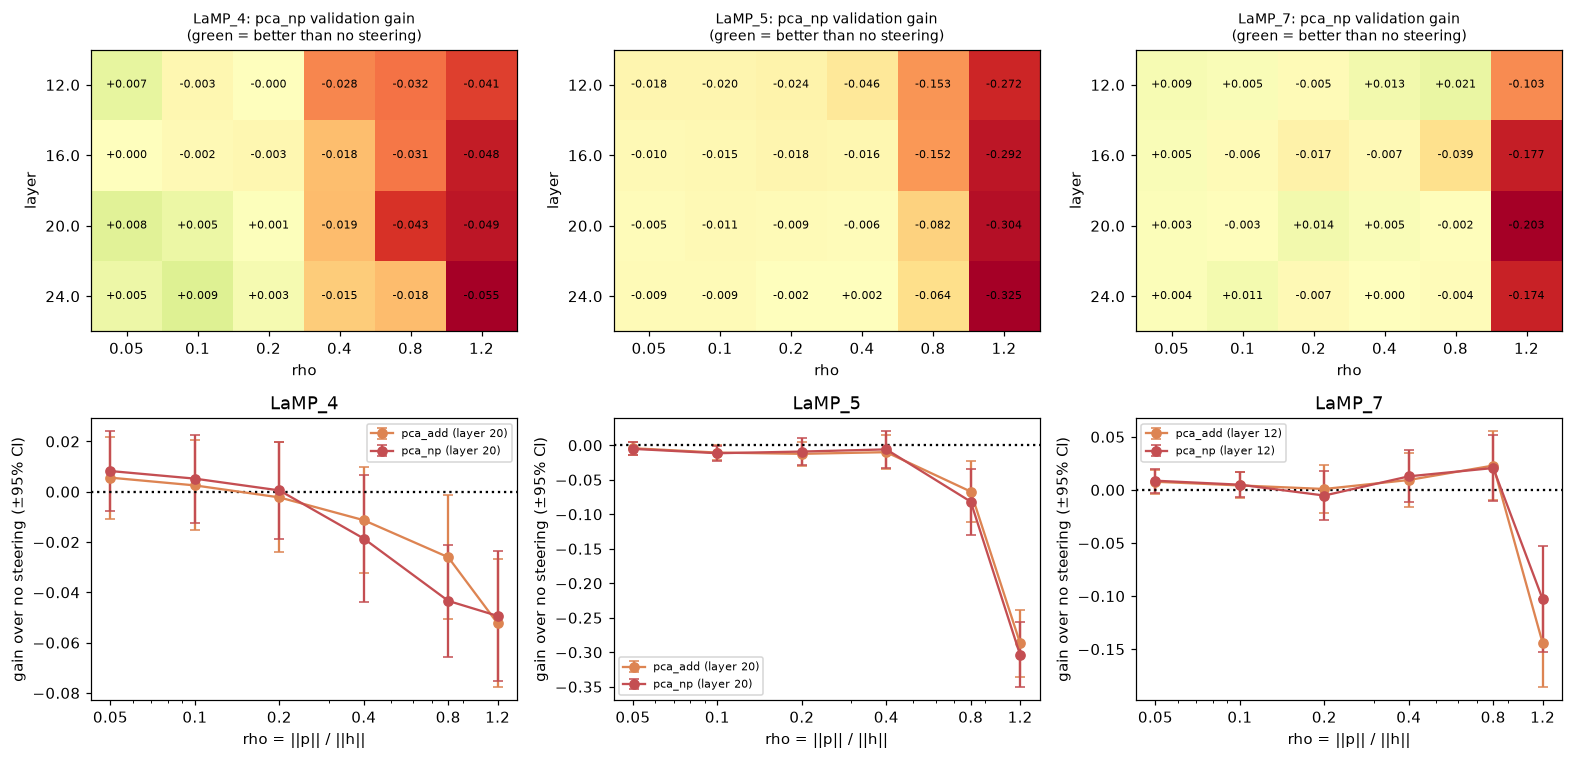

In [37]:
# Cell 5.3 — Validation plots: gain over no steering for every layer / strength
fig, axes = plt.subplots(2, len(TASKS), figsize=(4.8 * len(TASKS), 7), squeeze=False)
for j, task in enumerate(TASKS):
    g = gain_table(long_val, task, "pca_np")
    piv = g.pivot(index="layer", columns="rho", values="gain")
    ax = axes[0, j]
    im = ax.imshow(piv.values, aspect="auto", cmap="RdYlGn", vmin=-abs(piv.values).max(), vmax=abs(piv.values).max())
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{c:g}" for c in piv.columns])
    ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
    for (a, b), v in np.ndenumerate(piv.values):
        ax.text(b, a, f"{v:+.3f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{task}: pca_np validation gain\n(green = better than no steering)", fontsize=9); ax.set_xlabel("rho"); ax.set_ylabel("layer")

    ax = axes[1, j]
    for fam, colr in [("pca_add", "#dd8452"), ("pca_np", "#c44e52")]:
        L = TUNED[task][fam]["layer"]
        gg = gain_table(long_val, task, fam)
        gg = gg[gg.layer == L]
        ax.errorbar(gg.rho, gg.gain, yerr=1.96 * gg.sd / np.sqrt(gg.n), fmt="o-", color=colr, capsize=3, label=f"{fam} (layer {L})")
    ax.axhline(0, color="k", ls=":")
    ax.set_xscale("log"); ax.set_xticks(RHO_GRID); ax.set_xticklabels([f"{r:g}" for r in RHO_GRID]); ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("rho = ||p|| / ||h||"); ax.set_ylabel("gain over no steering (±95% CI)"); ax.set_title(task)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "validation_gain.png", dpi=150); plt.show()

In [38]:
# Cell 5.4 — TEST: base, pca_add, pca_np (each at its own validation setting) and the random-direction control
def test_configs(task):
    cfgs = OrderedDict(base=None)
    for fam in FAMILIES:
        cfgs[fam] = spec(fam, TUNED[task][fam]["layer"], TUNED[task][fam]["rho"])
    cfgs["random_np"] = spec("random_np", TUNED[task]["pca_np"]["layer"], TUNED[task]["pca_np"]["rho"])   # same layer & strength as ours
    return cfgs

for task in TASKS:
    run_experiment("test", task, test_users[task], test_configs(task))

test/LaMP_4: 100%|██████████| 300/300 [00:00<00:00, 3400787.03it/s]


test/LaMP_4: 0 new users (300 total)


test/LaMP_5: 100%|██████████| 300/300 [00:00<00:00, 492867.69it/s]


[411829] ERROR, skipping: name 'model' is not defined
test/LaMP_5: 0 new users (299 total)


test/LaMP_7: 100%|██████████| 300/300 [00:00<00:00, 3859788.96it/s]

test/LaMP_7: 0 new users (300 total)


## Part 6 — Results (test users only)

In [39]:
# Cell 6.1 — Scores and relative change over no steering
long_test = load_long("test", TASKS)
ORDER = ["base", "pca_add", "pca_np", "random_np"]

def paired_bootstrap(diff, n_boot=5000, seed=0):
    diff = np.asarray(diff, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(diff), (n_boot, len(diff)))
    lo, hi = np.percentile(diff[idx].mean(1), [2.5, 97.5])
    return diff.mean(), lo, hi

def vs(long, a, b, task, metric):
    """a minus b, paired per user. Returns mean diff, CI, and the same as a % of b's mean."""
    w = long[long.task == task].pivot(index="user_id", columns="config", values=metric)
    d = (w[a] - w[b]).dropna()
    mean, lo, hi = paired_bootstrap(d.values)
    ref = w.loc[d.index, b].mean()
    return dict(diff=mean, lo=lo, hi=hi, rel=100 * mean / ref, rel_lo=100 * lo / ref, rel_hi=100 * hi / ref, n=len(d))

rows = []
for task in TASKS:
    for cfg in ORDER:
        s = long_test[(long_test.task == task) & (long_test.config == cfg)]
        w = long_test[long_test.task == task].pivot(index="user_id", columns="config", values="pred")
        row = {"Task": task, "Config": cfg, "ROUGE-L": s.rougeL.mean(), "METEOR": s.meteor.mean(), "n": s.user_id.nunique(),
               "output changed vs base %": 100 * (w[cfg] != w["base"]).mean()}
        if cfg != "base":
            for metric, name in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
                row[f"{name} Δ% vs base"] = vs(long_test, cfg, "base", task, metric)["rel"]
        rows.append(row)
summary_test = pd.DataFrame(rows)
summary_test.round(4)

,Task,Config,ROUGE-L,METEOR,n,output changed vs base %,ROUGE-L Δ% vs base,METEOR Δ% vs base
0,LaMP_4,base,0.1098,0.0966,300,0.0000,NaN,NaN
1,LaMP_4,pca_add,0.1132,0.1027,300,29.6667,3.0667,6.3290
2,LaMP_4,pca_np,0.1123,0.1020,300,25.3333,2.2609,5.5992
3,LaMP_4,random_np,0.1092,0.0964,300,31.0000,-0.6249,-0.1651
4,LaMP_5,base,0.3196,0.3348,299,0.0000,NaN,NaN
5,LaMP_5,pca_add,0.3205,0.3346,299,24.0803,0.2761,-0.0535
6,LaMP_5,pca_np,0.3197,0.3340,299,25.7525,0.0288,-0.2299
7,LaMP_5,random_np,0.3209,0.3344,299,14.7157,0.4131,-0.1202
8,LaMP_7,base,0.2938,0.2618,300,0.0000,NaN,NaN
9,LaMP_7,pca_add,0.2975,0.2668,300,36.3333,1.2545,1.9062


In [40]:
# Cell 6.2 — MAIN RESULT: our improvement over no steering vs. the paper's StyleVector improvement
rows = []
for task in TASKS:
    for fam in ["pca_np", "pca_add"]:
        for metric, name in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
            r, paper = vs(long_test, fam, "base", task, metric), PAPER_IMPROVEMENT[task][name]
            verdict = "ours above paper" if r["rel_lo"] > paper else ("ours below paper" if r["rel_hi"] < paper else "paper value inside our CI")
            rows.append({"Task": task, "Metric": name, "Method": fam, "Paper StyleVector Δ%": paper,
                         "Ours Δ%": r["rel"], "Ours 95% CI lo": r["rel_lo"], "Ours 95% CI hi": r["rel_hi"],
                         "Ours > 0 (significant)?": r["rel_lo"] > 0, "vs paper": verdict, "n": r["n"]})
paper_cmp = pd.DataFrame(rows)
print("Δ% = relative improvement over the non-personalised model. 'paper value inside our CI' = our data cannot tell us and the paper apart.")
paper_cmp.round(2)

Δ% = relative improvement over the non-personalised model. 'paper value inside our CI' = our data cannot tell us and the paper apart.


,Task,Metric,Method,Paper StyleVector Δ%,Ours Δ%,Ours 95% CI lo,Ours 95% CI hi,Ours > 0 (significant)?,vs paper,n
0,LaMP_4,ROUGE-L,pca_np,3.2,2.26,-1.94,7.39,False,paper value inside our CI,300
1,LaMP_4,METEOR,pca_np,2.5,5.60,-0.12,12.96,False,paper value inside our CI,300
2,LaMP_4,ROUGE-L,pca_add,3.2,3.07,-2.07,8.74,False,paper value inside our CI,300
3,LaMP_4,METEOR,pca_add,2.5,6.33,0.11,14.00,True,paper value inside our CI,300
4,LaMP_5,ROUGE-L,pca_np,25.8,0.03,-1.42,1.50,False,ours below paper,299
5,LaMP_5,METEOR,pca_np,10.2,-0.23,-2.71,2.24,False,ours below paper,299
6,LaMP_5,ROUGE-L,pca_add,25.8,0.28,-1.14,1.69,False,ours below paper,299
7,LaMP_5,METEOR,pca_add,10.2,-0.05,-2.34,2.24,False,ours below paper,299
8,LaMP_7,ROUGE-L,pca_np,12.8,1.71,-0.23,3.61,False,ours below paper,300
9,LaMP_7,METEOR,pca_np,17.5,2.29,0.16,4.51,True,ours below paper,300


In [41]:
# Cell 6.3 — Is our method better than its own ablations and than a random direction? (paired differences, % of the second config)
pairs = [("pca_np", "pca_add", "norm preservation on top of PCA"),
         ("pca_np", "random_np", "our direction vs. a RANDOM direction (same layer and strength)"),
         ("pca_add", "base", "PCA, additive, vs. no steering"),
         ("pca_np", "base", "OUR FULL METHOD vs. no steering")]
rows = []
for a, b, q in pairs:
    for task in TASKS:
        for metric, name in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
            r = vs(long_test, a, b, task, metric)
            rows.append({"Question": q, "Task": task, "Metric": name, "A": a, "B": b, "mean diff": r["diff"],
                         "95% CI lo": r["lo"], "95% CI hi": r["hi"],
                         "verdict": "A better" if r["lo"] > 0 else ("A worse" if r["hi"] < 0 else "inconclusive")})
comparisons = pd.DataFrame(rows)
comparisons.round(4)

,Question,Task,Metric,A,B,mean diff,95% CI lo,95% CI hi,verdict
0,norm preservation on top of PCA,LaMP_4,ROUGE-L,pca_np,pca_add,-0.0009,-0.0041,0.0024,inconclusive
1,norm preservation on top of PCA,LaMP_4,METEOR,pca_np,pca_add,-0.0007,-0.0032,0.0018,inconclusive
2,norm preservation on top of PCA,LaMP_5,ROUGE-L,pca_np,pca_add,-0.0008,-0.0018,-0.0001,A worse
3,norm preservation on top of PCA,LaMP_5,METEOR,pca_np,pca_add,-0.0006,-0.0040,0.0023,inconclusive
4,norm preservation on top of PCA,LaMP_7,ROUGE-L,pca_np,pca_add,0.0013,0.0000,0.0032,inconclusive
5,norm preservation on top of PCA,LaMP_7,METEOR,pca_np,pca_add,0.0010,-0.0001,0.0027,inconclusive
6,our direction vs. a RANDOM direction (same lay...,LaMP_4,ROUGE-L,pca_np,random_np,0.0032,-0.0021,0.0085,inconclusive
7,our direction vs. a RANDOM direction (same lay...,LaMP_4,METEOR,pca_np,random_np,0.0056,0.0000,0.0110,A better
8,our direction vs. a RANDOM direction (same lay...,LaMP_5,ROUGE-L,pca_np,random_np,-0.0012,-0.0077,0.0051,inconclusive
9,our direction vs. a RANDOM direction (same lay...,LaMP_5,METEOR,pca_np,random_np,-0.0004,-0.0095,0.0088,inconclusive


In [42]:
# Cell 6.4 — Settings used + effect of output cleaning on the unsteered model
print("Settings chosen on validation users:")
display(tuned_tbl[["Task", "Method", "layer", "rho"]])
rows = []
for task in TASKS:
    s = long_test[(long_test.task == task) & (long_test.config == "base")]
    rows.append({"Task": task, "ROUGE-L raw": s.rougeL_raw.mean(), "ROUGE-L cleaned": s.rougeL.mean(),
                 "METEOR raw": s.meteor_raw.mean(), "METEOR cleaned": s.meteor.mean(),
                 "words raw": s.raw.str.split().str.len().mean(), "words cleaned": s.pred.str.split().str.len().mean(),
                 "words gold": s.gold.str.split().str.len().mean()})
print("\nUnsteered model: raw vs. cleaned output")
pd.DataFrame(rows).round(4)

Settings chosen on validation users:


,Task,Method,layer,rho
0,LaMP_4,pca_add,20,0.05
1,LaMP_4,pca_np,20,0.05
2,LaMP_5,pca_add,20,0.05
3,LaMP_5,pca_np,20,0.05
4,LaMP_7,pca_add,12,0.05
5,LaMP_7,pca_np,12,0.05



Unsteered model: raw vs. cleaned output


,Task,ROUGE-L raw,ROUGE-L cleaned,METEOR raw,METEOR cleaned,words raw,words cleaned,words gold
0,LaMP_4,0.0960,0.1098,0.1157,0.0966,23.1433,12.2167,9.6600
1,LaMP_5,0.2113,0.3196,0.3152,0.3348,24.6522,10.8194,8.6890
2,LaMP_7,0.2470,0.2938,0.2681,0.2618,20.3367,14.2633,16.9333


In [43]:
# Cell 6.5 — A few examples
for task in TASKS:
    print(f"\n{'='*20} {task} {'='*20}")
    sub = long_test[long_test.task == task]
    w = sub.pivot(index="user_id", columns="config", values="pred")
    gold = sub.drop_duplicates("user_id").set_index("user_id")["gold"]
    for uid, row in w[w["pca_np"] != w["base"]].head(3).iterrows():
        print(f"\n[user {uid}]\n  gold      : {gold[uid][:90]!r}")
        for c in ["base", "pca_np", "random_np"]:
            print(f"  {c:<9s} : {row[c][:90]!r}")


==================== LaMP_4 ====================

[user 311017]
  gold      : 'Celery Root Remoulade Recipe'
  base      : '1. "French Delicacy Finds Its Way to Your Plate: Introdu'
  pca_np    : '1. "French Delicacy Found: Celery Root Remoulade Recipe Un'
  random_np : '1. "French Delicacy Found: Celery Root Remoulade Recipe Un'

[user 311018]
  gold      : 'How To Make A Grilled Caesar Salad'
  base      : "everybody's favorite salad is now a crunchy snack!"
  pca_np    : "everybody's favorite salad green is getting a chill:"
  random_np : "everybody's favorite salad is now a crunchy snack!"

[user 311028]
  gold      : 'Paul Ryan Pledges 9/11 Bill Is All But Done'
  base      : '1. "Two Hurdles Remain: Will Bill Make It to Vote and How to Pay for It?'
  pca_np    : '1. "Two Hurdles Remain: Will Bill Reach Vote and How to Pay for It?'
  random_np : '1. "Two Hurdles Remain: Will Bill Reach Vote and How to Pay for It?'

==================== LaMP_5 ====================

[user 411038]
 

## Part 7 — Save

In [44]:
long_val.to_csv(CHECKPOINT_DIR / "val_long.csv", index=False)
long_test.to_csv(CHECKPOINT_DIR / "test_long.csv", index=False)
summary_test.to_csv(CHECKPOINT_DIR / "summary_test.csv", index=False)
paper_cmp.to_csv(CHECKPOINT_DIR / "comparison_with_paper.csv", index=False)
comparisons.to_csv(CHECKPOINT_DIR / "paired_comparisons.csv", index=False)
tuned_tbl.to_csv(CHECKPOINT_DIR / "tuned_settings.csv", index=False)
print("Saved to", CHECKPOINT_DIR.resolve())
del model
torch.cuda.empty_cache()

Saved to /home/user/stylevector_project/checkpoints_v3


NameError: name 'model' is not defined